In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V12'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
def misr_S_1(y):
    return np.diag(1 / (0.04 * y)**2)

camera = np.array([])
chi2 = np.array([])
source = np.array([])

exp_name = np.array([])
chi2_exp = np.array([])
for r in list(exset.retrievals.values()):
    cam_tmp, chi2_tmp = r.get_chi2_by_camera(misr_S_1, 'MISR',  'I')
    source_tmp = [r.exp_name] * len(chi2_tmp)
    camera = np.append(camera, cam_tmp)
    chi2 = np.append(chi2, chi2_tmp)
    source = np.append(source, source_tmp)

    chi2_exp_tmp = r.get_chi2(misr_S_1, 'I')
    exp_name = np.append(exp_name, r.exp_name)
    chi2_exp = np.append(chi2_exp, chi2_exp_tmp)

df = pd.DataFrame({'camera':camera, 'chi2':chi2, 'source':source})
df_overall = pd.DataFrame({'exp_name':exp_name, 'chi2':chi2_exp}).set_index('exp_name')

In [5]:
sublist = ['default', 'unconstrained', 'periodic', 'surf4p0', 'aod0p150', 'aod0p250', 'ATM', 'ATP', 'CTM', 'CTP']
df_mod = df[df['source'].isin(sublist)].pivot(columns='source', index='camera', values='chi2')

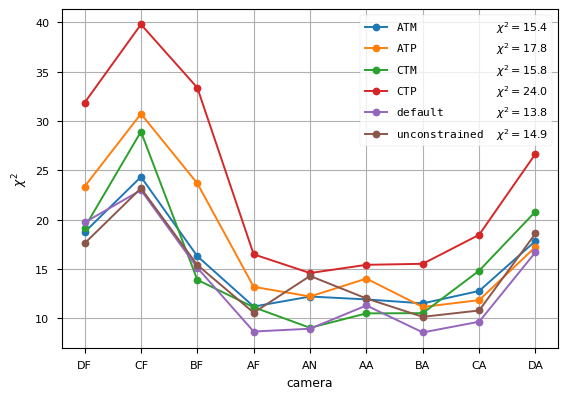

In [ ]:
cam_order = ['DF', 'CF', 'BF', 'AF', 'AN', 'AA', 'BA', 'CA', 'DA']
ax = df_mod.loc[cam_order].plot(kind='line', marker='o')
ax.grid()
ax.set_ylabel(r'$\chi^2$')

leg = ax.legend()

# find max label width so padding is consistent
labels = [t.get_text() for t in leg.get_texts()]
max_len = max(len(l) for l in labels)

for text in leg.get_texts():
    tmp_ex = text.get_text()
    tmp_chi2 = df_overall.loc[tmp_ex]['chi2']
    text.set_text(fr'{tmp_ex:<{max_len}}  $\chi^2={tmp_chi2:6.1f}$')
    text.set_fontfamily('monospace')

In [10]:
exp_name = []
u = []
v = []
for r in exset.retrievals.values():
    exp_name.append(r.exp_name)
    u.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_u)
    v.append(r.sensors_retrieval['MISR']['sensor_list'][0].wind_correction_v)
ds_ws = pd.DataFrame(data={
    'exp_name': exp_name,
    'u': u,
    'v': v
})
ds_ws = ds_ws.set_index('exp_name')
ds_ws = ds_ws.join(df_overall)

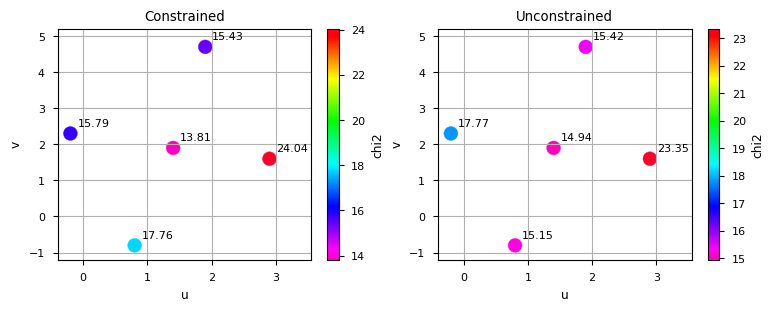

In [35]:
cmap = 'gist_rainbow_r'
f, ax = plt.subplots(1, 2, figsize=(9,3))

df1 = ds_ws.loc[['ATM','ATP','CTM','CTP','default']]
df1.plot.scatter(x='u', y='v', c='chi2', s=100, cmap=cmap, ax=ax[0])
ax[0].set_title('Constrained')
for idx, row in df1.iterrows():
    ax[0].annotate(f"{row['chi2']:.2f}", (row['u'], row['v']),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)

df2 = ds_ws.loc[['ATM_unc','ATP_unc','CTM_unc','CTP_unc','unconstrained']]
df2.plot.scatter(x='u', y='v', c='chi2', s=100, cmap=cmap, ax=ax[1])
ax[1].set_title('Unconstrained')
for idx, row in df2.iterrows():
    ax[1].annotate(f"{row['chi2']:.2f}", (row['u'], row['v']),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)

for a in ax.flatten():
    a.grid()
    a.set_xlim([-0.4, 3.55])
    a.set_ylim([-1.2, 5.2])